In [1]:
#Import Statements
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from sklearn.inspection import permutation_importance

print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.1


In [2]:
#Loading AAPL Daily Data
data = pd.read_csv(
    "../data/raw/AAPL_daily_raw.csv",
    index_col="Date",
    parse_dates=True
)

data.index = pd.to_datetime(data.index, utc=True).tz_localize(None)
data = data.sort_index()

print("Shape:", data.shape)
print("Date range:", data.index.min(), "to", data.index.max())

data.head()

Shape: (2766, 9)
Date range: 2015-01-02 05:00:00 to 2025-12-31 05:00:00


,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,daily_return
Date,,,,,,,,,
2015-01-02 05:00:00,27.847500,27.860001,26.837500,27.332500,24.171755,212818400,0.0,0.0,NaN
2015-01-05 05:00:00,27.072500,27.162500,26.352501,26.562500,23.490799,257142000,0.0,0.0,-0.028172
2015-01-06 05:00:00,26.635000,26.857500,26.157499,26.565001,23.493013,263188400,0.0,0.0,0.000094
2015-01-07 05:00:00,26.799999,27.049999,26.674999,26.937500,23.822430,160423600,0.0,0.0,0.014022
2015-01-08 05:00:00,27.307501,28.037500,27.174999,27.972500,24.737757,237458000,0.0,0.0,0.038423


In [3]:
#Returnd, Moving Averages, and Other Features  
data["daily_return"] = data["Adj Close"].pct_change()

data["SMA_20"] = data["Adj Close"].rolling(20).mean()
data["SMA_50"] = data["Adj Close"].rolling(50).mean()
data["SMA_200"] = data["Adj Close"].rolling(200).mean()

data["EMA_12"] = (
    data["Adj Close"].ewm(span=12, adjust=False).mean()
)

data["EMA_26"] = (
    data["Adj Close"].ewm(span=26, adjust=False).mean()
)

data["price_to_SMA20"] = data["Adj Close"] / data["SMA_20"] - 1
data["SMA20_to_SMA50"] = data["SMA_20"] / data["SMA_50"] - 1

data["momentum_10d"] = (
    data["Adj Close"] / data["Adj Close"].shift(10) - 1
)

data["rolling_20d_volatility"] = (
    data["daily_return"].rolling(20).std()
)

data["return_lag_1"] = data["daily_return"].shift(1)
data["return_lag_5"] = data["daily_return"].shift(5)

In [4]:
#RSI and MACD
delta = data["Adj Close"].diff()

gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

avg_gain = gain.ewm(alpha=1 / 14, adjust=False).mean()
avg_loss = loss.ewm(alpha=1 / 14, adjust=False).mean()

rs = avg_gain / avg_loss.replace(0, np.nan)

data["RSI_14"] = 100 - 100 / (1 + rs)

data.loc[
    (avg_loss == 0) & (avg_gain > 0),
    "RSI_14"
] = 100

data["MACD"] = data["EMA_12"] - data["EMA_26"]

data["MACD_signal"] = (
    data["MACD"].ewm(span=9, adjust=False).mean()
)

data["MACD_hist"] = data["MACD"] - data["MACD_signal"]

In [5]:
#Bollinger Bands and Volume Features
rolling_std_20 = data["Adj Close"].rolling(20).std()

data["BB_upper"] = data["SMA_20"] + 2 * rolling_std_20
data["BB_lower"] = data["SMA_20"] - 2 * rolling_std_20

band_width = data["BB_upper"] - data["BB_lower"]

data["BB_percent_b"] = (
    (data["Adj Close"] - data["BB_lower"]) / band_width
)

data["volume_change"] = data["Volume"].pct_change()
data["volume_SMA20"] = data["Volume"].rolling(20).mean()

data["relative_volume"] = data["Volume"] / data["volume_SMA20"]

data = data.replace([np.inf, -np.inf], np.nan)

In [6]:
#Defining the Target Variable
data["future_return_1d"] = (
    data["Adj Close"].shift(-1) / data["Adj Close"] - 1
)

data["target_up"] = np.nan

valid_target = data["future_return_1d"].notna()

data.loc[valid_target, "target_up"] = (
    data.loc[valid_target, "future_return_1d"] > 0
).astype(int)

In [7]:
#Building the Model Dataset
feature_columns = [
    "daily_return",
    "return_lag_1",
    "return_lag_5",
    "rolling_20d_volatility",
    "SMA_20",
    "SMA_50",
    "SMA_200",
    "EMA_12",
    "EMA_26",
    "price_to_SMA20",
    "SMA20_to_SMA50",
    "momentum_10d",
    "RSI_14",
    "MACD",
    "MACD_signal",
    "MACD_hist",
    "BB_percent_b",
    "volume_change",
    "relative_volume"
]

model_data = data[
    feature_columns + ["future_return_1d", "target_up"]
].dropna().copy()

model_data["target_up"] = model_data["target_up"].astype(int)
model_data = model_data.sort_index()

print("Rows:", len(model_data))
print("Features:", len(feature_columns))

model_data.head()

Rows: 2566
Features: 19


,daily_return,return_lag_1,return_lag_5,rolling_20d_volatility,SMA_20,SMA_50,SMA_200,EMA_12,EMA_26,price_to_SMA20,...,momentum_10d,RSI_14,MACD,MACD_signal,MACD_hist,BB_percent_b,volume_change,relative_volume,future_return_1d,target_up
Date,,,,,,,,,,,,,,,,,,,,,
2015-10-16 04:00:00,-0.007330,0.014971,0.023927,0.013303,25.025021,25.154457,27.011853,24.921899,25.058386,-0.006526,...,0.005980,47.284859,-0.136487,-0.159463,0.022976,0.403032,0.041385,0.782110,0.006214,1
2015-10-19 04:00:00,0.006214,-0.007330,-0.004638,0.012851,24.986064,25.137486,27.016075,24.936404,25.055260,0.001205,...,0.008576,49.316799,-0.118856,-0.151341,0.032486,0.519810,-0.241468,0.605608,0.018258,1
2015-10-20 04:00:00,0.018258,0.006214,0.001703,0.013110,24.990206,25.110842,27.025986,25.018947,25.086199,0.019317,...,0.022101,54.857082,-0.067252,-0.134524,0.067272,0.813324,0.645468,0.997908,-0.000088,0
2015-10-21 04:00:00,-0.000088,0.018258,-0.014134,0.012978,24.983937,25.112051,27.035874,25.088446,25.114680,0.019483,...,0.026900,54.825440,-0.026233,-0.112866,0.086632,0.823909,-0.146476,0.846530,0.015295,1
2015-10-22 04:00:00,0.015295,-0.000088,0.014971,0.013372,24.989534,25.113215,27.046064,25.207189,25.169909,0.034844,...,0.054795,59.231391,0.037280,-0.082836,0.120117,1.060613,-0.003376,0.851054,0.030996,1


In [8]:
#Splitting the Data into Train, Validation, and Test Sets
n = len(model_data)

train_end = int(n * 0.70)
validation_end = int(n * 0.85)

train = model_data.iloc[:train_end].copy()
validation = model_data.iloc[train_end:validation_end].copy()
test = model_data.iloc[validation_end:].copy()

X_train = train[feature_columns]
X_validation = validation[feature_columns]
X_test = test[feature_columns]

y_train = train["target_up"]
y_validation = validation["target_up"]
y_test = test["target_up"]

print("Train:", train.index.min(), "to", train.index.max())
print("Validation:", validation.index.min(), "to", validation.index.max())
print("Test:", test.index.min(), "to", test.index.max())

assert train.index.max() < validation.index.min()
assert validation.index.max() < test.index.min()
assert y_train.nunique() == 2
assert y_validation.nunique() == 2

print("Chronological split checks passed.")

Train: 2015-10-16 04:00:00 to 2022-12-02 05:00:00
Validation: 2022-12-05 05:00:00 to 2024-06-17 04:00:00
Test: 2024-06-18 04:00:00 to 2025-12-30 05:00:00
Chronological split checks passed.


In [9]:
#Regularization Strengths and Model Candidates
regularization_strengths = [0.01, 0.1, 1.0, 10.0]

candidates = {}
candidate_results = []

for penalty_name, l1_ratio in [
    ("L2", 0.0),
    ("L1", 1.0)
]:
    for C in regularization_strengths:
        model_name = f"{penalty_name} (C={C})"

        candidate = Pipeline(steps=[
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(
                solver="saga",
                l1_ratio=l1_ratio,
                C=C,
                max_iter=10000,
                tol=0.001,
                random_state=42
            ))
        ])

        candidate.fit(X_train, y_train)

        candidates[model_name] = candidate

        train_predictions = candidate.predict(X_train)
        val_predictions = candidate.predict(X_validation)

        candidate_classes = list(
            candidate.named_steps["classifier"].classes_
        )
        up_index = candidate_classes.index(1)

        val_probability_up = candidate.predict_proba(
            X_validation
        )[:, up_index]

        candidate_results.append({
            "Model": model_name,
            "C": C,
            "Training Balanced Accuracy": balanced_accuracy_score(
                y_train, train_predictions
            ),
            "Validation Accuracy": accuracy_score(
                y_validation, val_predictions
            ),
            "Validation Balanced Accuracy": balanced_accuracy_score(
                y_validation, val_predictions
            ),
            "Validation Macro F1": f1_score(
                y_validation, val_predictions,
                average="macro", zero_division=0
            ),
            "Validation ROC-AUC": roc_auc_score(
                y_validation, val_probability_up
            )
        })

regularization_results = (
    pd.DataFrame(candidate_results)
    .set_index("Model")
)

regularization_results.round(4)

,C,Training Balanced Accuracy,Validation Accuracy,Validation Balanced Accuracy,Validation Macro F1,Validation ROC-AUC
Model,,,,,,
L2 (C=0.01),0.01,0.5286,0.5273,0.5165,0.5076,0.4860
L2 (C=0.1),0.10,0.5507,0.5039,0.4976,0.4954,0.4860
L2 (C=1.0),1.00,0.5531,0.4935,0.4878,0.4862,0.4895
L2 (C=10.0),10.00,0.5510,0.4883,0.4829,0.4815,0.4914
L1 (C=0.01),0.01,0.5000,0.5325,0.5000,0.3475,0.5000
L1 (C=0.1),0.10,0.5269,0.5455,0.5257,0.4870,0.4849
L1 (C=1.0),1.00,0.5536,0.4935,0.4878,0.4862,0.4833
L1 (C=10.0),10.00,0.5532,0.4909,0.4854,0.4839,0.4901


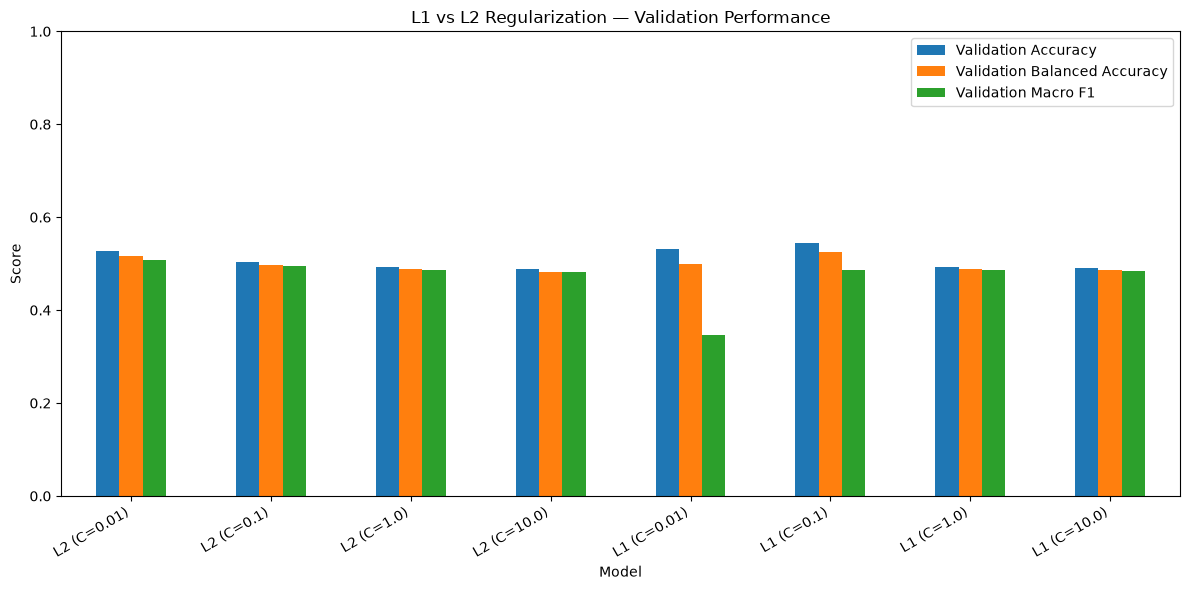

In [10]:
#Comparing L1 and L2 Regularization Performance
regularization_results[
    [
        "Validation Accuracy",
        "Validation Balanced Accuracy",
        "Validation Macro F1"
    ]
].plot(kind="bar", figsize=(12, 6))

plt.title("L1 vs L2 Regularization — Validation Performance")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [11]:
# Selecting the Best Model using validation balanced accuracy and macro F1 score
best_model_name = regularization_results.sort_values(
    [
        "Validation Balanced Accuracy",
        "Validation Macro F1"
    ],
    ascending=False
).index[0]

best_model = candidates[best_model_name]

print("Selected model:", best_model_name)
print(
    regularization_results.loc[best_model_name]
)

Selected model: L1 (C=0.1)
C                               0.100000
Training Balanced Accuracy      0.526910
Validation Accuracy             0.545455
Validation Balanced Accuracy    0.525745
Validation Macro F1             0.486960
Validation ROC-AUC              0.484905
Name: L1 (C=0.1), dtype: float64


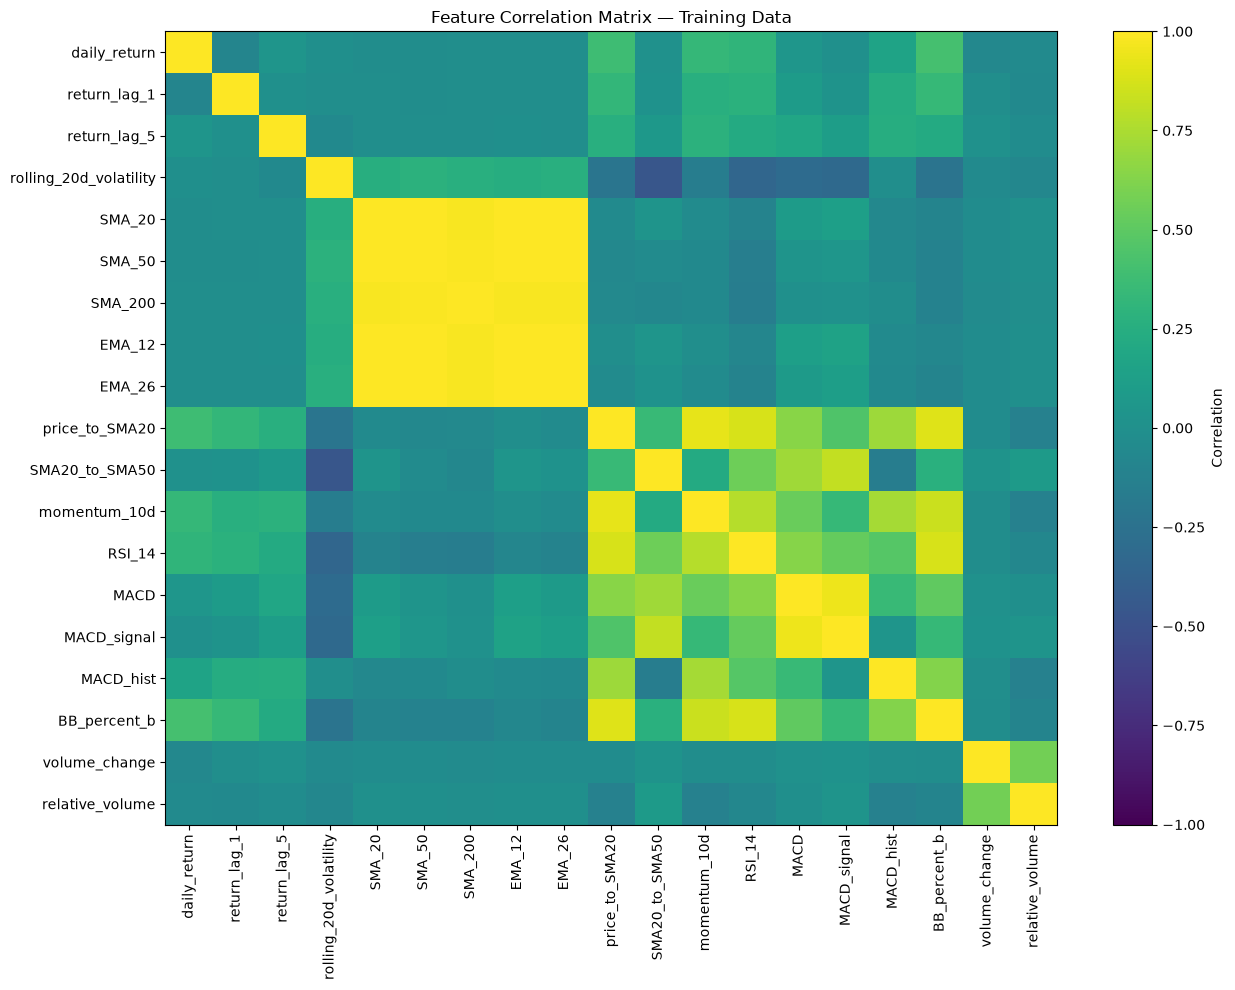

In [12]:
#Calculating correlation among features in the training dataset
feature_corr = X_train.corr()

plt.figure(figsize=(13, 10))

plt.imshow(
    feature_corr,
    vmin=-1,
    vmax=1,
    aspect="auto"
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(feature_corr.columns)),
    feature_corr.columns,
    rotation=90
)

plt.yticks(
    range(len(feature_corr.columns)),
    feature_corr.columns
)

plt.title("Feature Correlation Matrix — Training Data")
plt.tight_layout()
plt.show()

In [13]:
#Listing the strongest correlations among features in the training dataset
upper_triangle = feature_corr.abs().where(
    np.triu(
        np.ones(feature_corr.shape),
        k=1
    ).astype(bool)
)

top_correlated_pairs = (
    upper_triangle.stack()
    .sort_values(ascending=False)
    .head(15)
)

top_correlated_pairs

SMA_20          EMA_26          0.999758
                EMA_12          0.999363
EMA_12          EMA_26          0.999305
SMA_50          EMA_26          0.997843
SMA_20          SMA_50          0.996617
SMA_50          EMA_12          0.994931
                SMA_200         0.987360
SMA_200         EMA_26          0.982744
SMA_20          SMA_200         0.980417
SMA_200         EMA_12          0.978786
MACD            MACD_signal     0.950632
price_to_SMA20  momentum_10d    0.921998
                BB_percent_b    0.902400
RSI_14          BB_percent_b    0.879281
price_to_SMA20  RSI_14          0.875598
dtype: float64

In [14]:
#Analyzing Feature Importance Using Coefficients
selected_classifier = best_model.named_steps["classifier"]

coefficient_table = pd.DataFrame({
    "Feature": feature_columns,
    "Coefficient": selected_classifier.coef_[0]
})

coefficient_table["Absolute Coefficient"] = (
    coefficient_table["Coefficient"].abs()
)

coefficient_table = coefficient_table.sort_values(
    "Absolute Coefficient",
    ascending=False
)

coefficient_table

,Feature,Coefficient,Absolute Coefficient
0,daily_return,-0.120585,0.120585
16,BB_percent_b,0.089531,0.089531
13,MACD,-0.034037,0.034037
7,EMA_12,-0.026474,0.026474
17,volume_change,-0.013456,0.013456
1,return_lag_1,-0.009706,0.009706
2,return_lag_5,-0.006559,0.006559
6,SMA_200,0.000000,0.000000
3,rolling_20d_volatility,0.000000,0.000000
5,SMA_50,0.000000,0.000000


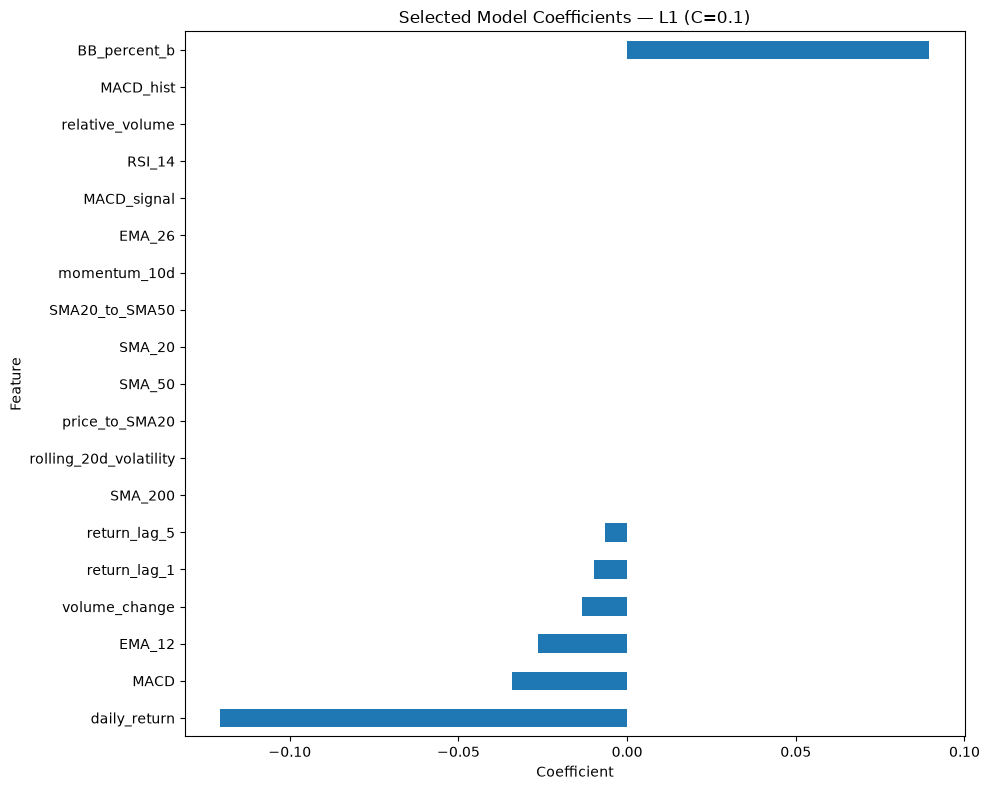

In [15]:
#Plotting the Coefficients of the Selected Model
coefficient_table.sort_values("Coefficient").plot(
    x="Feature",
    y="Coefficient",
    kind="barh",
    figsize=(10, 8),
    legend=False
)

plt.title(f"Selected Model Coefficients — {best_model_name}")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [16]:
#Calculate Permutation Importance of Features
permutation_result = permutation_importance(
    best_model,
    X_validation,
    y_validation,
    scoring="balanced_accuracy",
    n_repeats=10,
    random_state=42
)

importance_table = pd.DataFrame({
    "Feature": feature_columns,
    "Importance Mean": permutation_result.importances_mean,
    "Importance Std": permutation_result.importances_std
})

importance_table = importance_table.sort_values(
    "Importance Mean",
    ascending=False
)

importance_table

,Feature,Importance Mean,Importance Std
13,MACD,0.027710,0.008855
16,BB_percent_b,0.019797,0.018739
17,volume_change,0.019729,0.006299
0,daily_return,0.018699,0.021365
7,EMA_12,0.014160,0.006628
2,return_lag_5,0.008787,0.006457
1,return_lag_1,0.007846,0.006499
6,SMA_200,0.000000,0.000000
3,rolling_20d_volatility,0.000000,0.000000
5,SMA_50,0.000000,0.000000


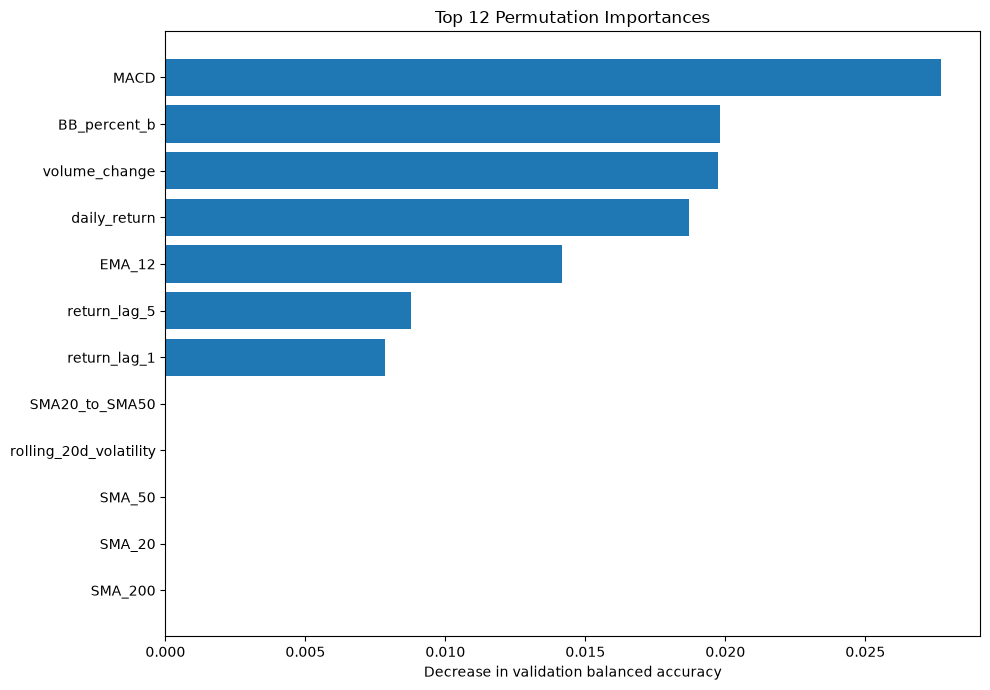

In [17]:
#Plotting the most Inflential Features Based on Permutation Importance
top_importance = importance_table.head(12).sort_values(
    "Importance Mean"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_importance["Feature"],
    top_importance["Importance Mean"]
)

plt.xlabel("Decrease in validation balanced accuracy")
plt.title("Top 12 Permutation Importances")
plt.tight_layout()
plt.show()

In [18]:
#Finding the Test Performance of the Selected Model
test_predictions = best_model.predict(X_test)

test_classes = list(
    best_model.named_steps["classifier"].classes_
)

test_up_index = test_classes.index(1)

test_probability_up = best_model.predict_proba(X_test)[
    :, test_up_index
]

final_test_results = {
    "Selected model": best_model_name,
    "Test accuracy": accuracy_score(
        y_test, test_predictions
    ),
    "Test balanced accuracy": balanced_accuracy_score(
        y_test, test_predictions
    ),
    "Test macro F1": f1_score(
        y_test, test_predictions,
        average="macro", zero_division=0
    ),
    "Test UP precision": precision_score(
        y_test, test_predictions,
        pos_label=1, zero_division=0
    ),
    "Test UP recall": recall_score(
        y_test, test_predictions,
        pos_label=1, zero_division=0
    )
}

if y_test.nunique() == 2:
    final_test_results["Test ROC-AUC"] = roc_auc_score(
        y_test, test_probability_up
    )

pd.Series(final_test_results)

Selected model            L1 (C=0.1)
Test accuracy               0.477922
Test balanced accuracy      0.471621
Test macro F1               0.471634
Test UP precision           0.530516
Test UP recall              0.528037
Test ROC-AUC                0.468957
dtype: object

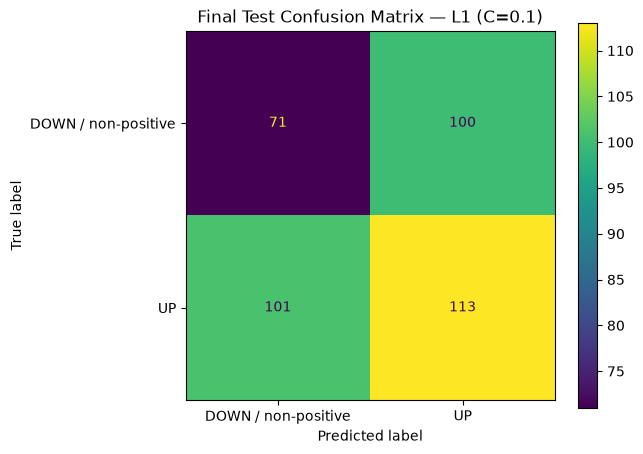

In [19]:
#Selected Model Confusion Matrix on Test Data
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["DOWN / non-positive", "UP"]
)

plt.title(f"Final Test Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()